# Bounds from Observed Outcomes

## Bounding effects with missing counterfactuals

For unit $i$, let $Y_i(1)$ be the outcome under treatment and let $Y_i(0)$ be the outcome under control. The individual treatment effect is

$$
\tau_i=Y_i(1)-Y_i(0).
$$

The symbol $\tau_i$ is the change for unit $i$ between its two potential outcomes. Only one potential outcome is observed because the treatment indicator $D_i$ takes either zero or one. The observed outcome is

$$
Y_i=D_iY_i(1)+(1-D_i)Y_i(0).
$$

Here, $Y_i$ is the recorded outcome and $D_i=1$ denotes treatment. This equality is the consistency relation used by the calculation. It does not state that treated and control units are exchangeable.

### Worst-Case Bounds

Suppose every potential outcome lies in the supplied interval $[L,U]$. For a treated unit, the missing control outcome can take any value in that interval. Its effect therefore lies between $Y_i-U$ and $Y_i-L$. For a control unit, the missing treated outcome gives the interval from $L-Y_i$ to $U-Y_i$. Averaging these unit ranges gives

$$
\underline\tau=\frac{1}{n}\sum_{i=1}^{n}\left[D_i(Y_i-U)+(1-D_i)(L-Y_i)\right],
$$

and

$$
\overline\tau=\frac{1}{n}\sum_{i=1}^{n}\left[D_i(Y_i-L)+(1-D_i)(U-Y_i)\right].
$$

The quantities $\underline\tau$ and $\overline\tau$ are the lower and upper limits for the empirical average treatment effect. The number of units is $n$, while $L$ and $U$ are supplied outcome limits. These are identification limits for the observed finite population, not sampling confidence limits.

#### Packages and notebook settings

In [ ]:
from pathlib import Path as _FigurePath
from sys import path as _figure_import_path

_figure_folder = _FigurePath.cwd()
_figure_root = next(
    folder for folder in (_figure_folder, *_figure_folder.parents)
    if (folder / "notebook_figures.py").is_file()
)
_figure_import_path.insert(0, str(_figure_root))
from notebook_figures import display_notebook_figure

from pathlib import Path
import itertools
import sys
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sensemakr
import statsmodels.api as sm
from IPython.display import HTML, display as _display

def display(value):
    module = value.__class__.__module__
    if module.startswith('pandas') and hasattr(value, '_repr_html_'):
        html = value._repr_html_()
        return _display(HTML('<div style="display:flex;justify-content:center;">' + html + '</div>'))
    return _display(value)
BOOK_ROOT = Path.cwd().parents[1]
if str(BOOK_ROOT) not in sys.path:
    sys.path.insert(0, str(BOOK_ROOT))
from book_support import ensure_dataset
FINANCIAL_ROOT = BOOK_ROOT
import RiskLabAI
from RiskLabAI.causal_factor_analysis import manski_ate_bounds
assert RiskLabAI.__version__ == '3.2.0'
FIGURES = BOOK_ROOT / 'outputs' / 'figures' / '05_partial_identification'
TABLES = BOOK_ROOT / 'outputs' / 'tables' / '05_partial_identification'
FIGURE_DATA = BOOK_ROOT / 'outputs' / 'figure_data' / '05_partial_identification'


#### Figure settings

In [ ]:
DATA_FILE = ensure_dataset(BOOK_ROOT, 'mpdta')
for directory in [FIGURES, TABLES, FIGURE_DATA]:
    directory.mkdir(parents=True, exist_ok=True)
PALETTE = {'background': '#111827', 'axes': '#111827', 'text': '#E5E7EB', 'cyan': '#38BDF8', 'amber': '#FBBF24', 'green': '#34D399', 'rose': '#FB7185', 'violet': '#C084FC', 'grid': '#374151'}
plt.rcParams.update({'font.family': 'DejaVu Serif', 'font.size': 11.5, 'figure.facecolor': PALETTE['background'], 'axes.facecolor': PALETTE['axes'], 'axes.edgecolor': PALETTE['text'], 'axes.labelcolor': PALETTE['text'], 'axes.titlecolor': PALETTE['text'], 'xtick.color': PALETTE['text'], 'ytick.color': PALETTE['text'], 'text.color': PALETTE['text'], 'grid.color': PALETTE['grid'], 'grid.linestyle': ':', 'legend.facecolor': PALETTE['axes'], 'legend.edgecolor': PALETTE['grid'], 'savefig.facecolor': PALETTE['background'], 'savefig.transparent': False, 'savefig.dpi': 300})
VAR_LOOKUP = {'year': 'Year', 'countyreal': 'County identifier', 'lpop': 'Log population', 'lemp': 'Log employment', 'first_treat': 'First treatment year', 'treat': 'Treatment indicator'}

def rendered_value(value):
    if pd.isna(value):
        return ''
    if isinstance(value, (bool, np.bool_)):
        return 'Pass' if bool(value) else 'Fail'
    if isinstance(value, (int, np.integer)):
        return f'{int(value):,}'
    if isinstance(value, (float, np.floating)):
        value = float(value)
        if value == 0:
            return '0'
        if value.is_integer():
            return f'{int(value):,}'
        if abs(value) < 0.0001 or abs(value) >= 1000000:
            return f'{value:.6g}'
        return f'{value:.6f}'.rstrip('0').rstrip('.')
    return str(value)



#### Table and figure formatting

In [ ]:
def rendered_frame(frame):
    return frame.apply(lambda column: column.map(rendered_value))

def save_table(frame, stem, caption, label, fit=False):
    shown = rendered_frame(frame)
    shown.to_csv(TABLES / f'{stem}.csv', index=False)
    latex = shown.to_latex(index=False, escape=True, caption=caption, label=label, position='htbp')
    latex = latex.replace('\\begin{table}[htbp]', '\\begin{table}[htbp]\n\\centering', 1)
    if fit:
        latex = latex.replace('\\begin{tabular}', '\\begin{adjustbox}{max width=\\textwidth}\\begin{tabular}', 1).replace('\\end{tabular}', '\\end{tabular}\\end{adjustbox}', 1)
    (TABLES / f'{stem}.tex').write_text(latex, encoding='utf-8')
    display(shown)
    return shown

def finish_axis(axis, grid=True):
    axis.spines['top'].set_visible(False)
    axis.spines['right'].set_visible(False)
    if grid:
        axis.grid(True, alpha=0.65)
    axis.set_axisbelow(True)

def save_figure(figure, stem):
    figure.savefig(FIGURES / f'{stem}.png', dpi=300, bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    figure.savefig(FIGURES / f'{stem}.pdf', bbox_inches='tight', facecolor=PALETTE['background'], transparent=False)
    display_notebook_figure(figure)
    plt.close(figure)



#### County frame

In [ ]:
def county_frame():
    raw = pd.read_csv(DATA_FILE)
    employment = raw.pivot(index='countyreal', columns='year', values='lemp')
    population = raw.pivot(index='countyreal', columns='year', values='lpop')
    first_treatment = raw.groupby('countyreal')['first_treat'].first()
    frame = pd.DataFrame({'County identifier': employment.index, 'Treatment group': (first_treatment.reindex(employment.index).to_numpy() > 0).astype(int), 'Log employment in 2003': employment[2003].to_numpy(), 'Log employment in 2006': employment[2006].to_numpy(), 'Log employment in 2007': employment[2007].to_numpy(), 'Log population in 2003': population[2003].to_numpy()})
    frame['Employment change, 2003 to 2007'] = frame['Log employment in 2007'] - frame['Log employment in 2003']
    frame['Employment increased, 2006 to 2007'] = (frame['Log employment in 2007'] > frame['Log employment in 2006']).astype(int)
    return (raw, frame)

def partial_r2(restricted, expanded):
    return float(1 - expanded.ssr / restricted.ssr)



#### Assumptions and limits of the bounded-outcome calculation

,Symbol,Description
0,Y_i(1),Potential outcome for unit i under treatment
1,Y_i(0),Potential outcome for unit i under control
2,D_i,Binary treatment indicator for unit i
3,Y_i,Observed outcome for unit i
4,L,Supplied lower outcome limit
5,U,Supplied upper outcome limit
6,tau_i,Individual treatment effect
7,"underline tau, overline tau",Lower and upper empirical average-effect limits


,Requirement,Role
0,Consistency,Connects the observed outcome to the potential...
1,Binary treatment,Separates treated and control potential outcomes
2,Supplied outcome interval,Restricts every observed and missing potential...
3,Treatment exchangeability,Not required by the worst-case calculation
4,Sampling model,Not supplied; the result is not a confidence i...


,Missing value for unit 1,Missing value for unit 2,Missing value for unit 3,Average treatment effect
0,0,0,0,-0.033333
1,0,0,1,-0.366667
2,0,1,0,0.3
3,0,1,1,-0.033333
4,1,0,0,-0.366667
5,1,0,1,-0.7
6,1,1,0,-0.033333
7,1,1,1,-0.366667


,Quantity,Value
0,Released lower limit,-0.7
1,Enumerated minimum,-0.7
2,Released upper limit,0.3
3,Enumerated maximum,0.3
4,Treatment fraction,0.666667
5,Unit count,3


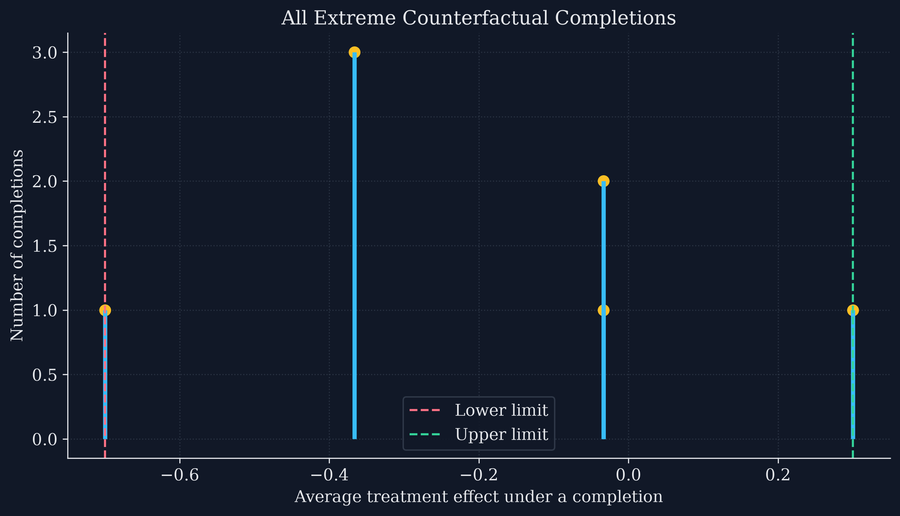

In [1]:
def scalar(value):
    return float(np.asarray(value).item())
notation = pd.DataFrame([{'Symbol': 'Y_i(1)', 'Description': 'Potential outcome for unit i under treatment'}, {'Symbol': 'Y_i(0)', 'Description': 'Potential outcome for unit i under control'}, {'Symbol': 'D_i', 'Description': 'Binary treatment indicator for unit i'}, {'Symbol': 'Y_i', 'Description': 'Observed outcome for unit i'}, {'Symbol': 'L', 'Description': 'Supplied lower outcome limit'}, {'Symbol': 'U', 'Description': 'Supplied upper outcome limit'}, {'Symbol': 'tau_i', 'Description': 'Individual treatment effect'}, {'Symbol': 'underline tau, overline tau', 'Description': 'Lower and upper empirical average-effect limits'}])
save_table(notation, 'manski_notation', 'Notation for bounded-outcome identification.', 'tab:cim5-manski-notation', fit=True)
assumptions = pd.DataFrame([{'Requirement': 'Consistency', 'Role': 'Connects the observed outcome to the potential outcome under the received treatment'}, {'Requirement': 'Binary treatment', 'Role': 'Separates treated and control potential outcomes'}, {'Requirement': 'Supplied outcome interval', 'Role': 'Restricts every observed and missing potential outcome to L through U'}, {'Requirement': 'Treatment exchangeability', 'Role': 'Not required by the worst-case calculation'}, {'Requirement': 'Sampling model', 'Role': 'Not supplied; the result is not a confidence interval'}])
save_table(assumptions, 'manski_assumptions', 'Assumptions and limits of the bounded-outcome calculation.', 'tab:cim5-manski-assumptions', fit=True)
observed = np.array([0.2, 0.8, 0.5])
treatment = np.array([1, 0, 1])
records = []
for missing in itertools.product([0.0, 1.0], repeat=3):
    y1 = np.where(treatment == 1, observed, missing)
    y0 = np.where(treatment == 1, missing, observed)
    records.append({'Missing value for unit 1': missing[0], 'Missing value for unit 2': missing[1], 'Missing value for unit 3': missing[2], 'Average treatment effect': np.mean(y1 - y0)})
enumeration = pd.DataFrame(records)
bounds = manski_ate_bounds(observed, treatment, lower=0, upper=1)
assert np.isclose(bounds['lower'], enumeration['Average treatment effect'].min())
assert np.isclose(bounds['upper'], enumeration['Average treatment effect'].max())
save_table(enumeration, 'manski_exact_enumeration', 'Extreme missing-potential-outcome enumeration for three units.', 'tab:cim5-manski-enumeration', fit=True)
exact_summary = pd.DataFrame([{'Quantity': 'Released lower limit', 'Value': bounds['lower']}, {'Quantity': 'Enumerated minimum', 'Value': enumeration['Average treatment effect'].min()}, {'Quantity': 'Released upper limit', 'Value': bounds['upper']}, {'Quantity': 'Enumerated maximum', 'Value': enumeration['Average treatment effect'].max()}, {'Quantity': 'Treatment fraction', 'Value': bounds['treated_fraction']}, {'Quantity': 'Unit count', 'Value': bounds['sample_count']}])
save_table(exact_summary, 'manski_exact_summary', 'Exact comparison of released and enumerated limits.', 'tab:cim5-manski-exact-summary')
enum_plot = enumeration.groupby('Average treatment effect', as_index=False).size().rename(columns={'size': 'Completions'})
enum_plot.to_csv(FIGURE_DATA / 'manski_exact_distribution.csv', index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.0), constrained_layout=True)
axis.vlines(enum_plot['Average treatment effect'], 0, enum_plot['Completions'], color=PALETTE['cyan'], linewidth=3)
axis.scatter(enum_plot['Average treatment effect'], enum_plot['Completions'], color=PALETTE['amber'], s=55)
axis.axvline(bounds['lower'], color=PALETTE['rose'], linestyle='--', label='Lower limit')
axis.axvline(bounds['upper'], color=PALETTE['green'], linestyle='--', label='Upper limit')
axis.set_xlabel('Average treatment effect under a completion')
axis.set_ylabel('Number of completions')
axis.set_title('All Extreme Counterfactual Completions')
axis.legend()
finish_axis(axis)
save_figure(figure, 'manski_exact_distribution')


## How boundary cases change the width of the effect region

Every unit-level interval has width $U-L$. The empirical average interval therefore has width

$$
\overline\tau-\underline\tau=U-L.
$$

This equality explains why a wider supplied outcome range directly widens the identification region. The treated fraction and observed group means move the location of the region, but without another assumption they cannot reduce its worst-case width.

### Boundary cases accepted by the released calculation

In [2]:
boundary_cases = []
for name, y, d, lower, upper in [
    ("All treated", [1, 1], [1, 1], 0, 1),
    ("All control", [0, 0], [0, 0], 0, 1),
    ("Constant outcome range", [2, 2], [0, 1], 2, 2),
    ("Mixed binary outcomes", [0, 1, 1, 0], [0, 0, 1, 1], 0, 1),
]:
    result = manski_ate_bounds(y, d, lower=lower, upper=upper)
    boundary_cases.append({"Case": name, "Lower limit": result["lower"], "Upper limit": result["upper"], "Treatment fraction": result["treated_fraction"], "Unit count": result["sample_count"]})
boundary_frame = pd.DataFrame(boundary_cases)
save_table(boundary_frame, "manski_boundary_cases", "Boundary cases accepted by the released calculation.", "tab:cim5-manski-boundary-cases", fit=True)

invalid_checks = []
for name, arguments in [
    ("Observed outcome above upper limit", ([2], [1], 0, 1)),
    ("Treatment value outside zero and one", ([0.5], [2], 0, 1)),
    ("Reversed outcome limits", ([0.5], [1], 1, 0)),
    ("Mismatched array lengths", ([0.5, 0.4], [1], 0, 1)),
]:
    passed = False
    try:
        manski_ate_bounds(arguments[0], arguments[1], lower=arguments[2], upper=arguments[3])
    except ValueError:
        passed = True
    invalid_checks.append({"Check": name, "Rejected": passed})
invalid_frame = pd.DataFrame(invalid_checks)
assert invalid_frame["Rejected"].all()
save_table(invalid_frame, "manski_invalid_input_checks", "Invalid-input checks for the bounded-outcome calculation.", "tab:cim5-manski-invalid-checks", fit=True);



,Case,Lower limit,Upper limit,Treatment fraction,Unit count
0,All treated,0,1,1,2
1,All control,0,1,0,2
2,Constant outcome range,0,0,0.5,2
3,Mixed binary outcomes,-0.5,0.5,0.5,4


,Check,Rejected
0,Observed outcome above upper limit,Pass
1,Treatment value outside zero and one,Pass
2,Reversed outcome limits,Pass
3,Mismatched array lengths,Pass


### Identification limits as the supplied upper outcome limit changes

,Upper outcome limit,Lower effect limit,Upper effect limit,Region width
0,0.8,-0.566667,0.233333,0.8
1,0.9,-0.633333,0.266667,0.9
2,1,-0.7,0.3,1
3,1.1,-0.766667,0.333333,1.1
4,1.2,-0.833333,0.366667,1.2
5,1.3,-0.9,0.4,1.3
6,1.4,-0.966667,0.433333,1.4
7,1.5,-1.033333,0.466667,1.5
8,1.6,-1.1,0.5,1.6
9,1.7,-1.166667,0.533333,1.7


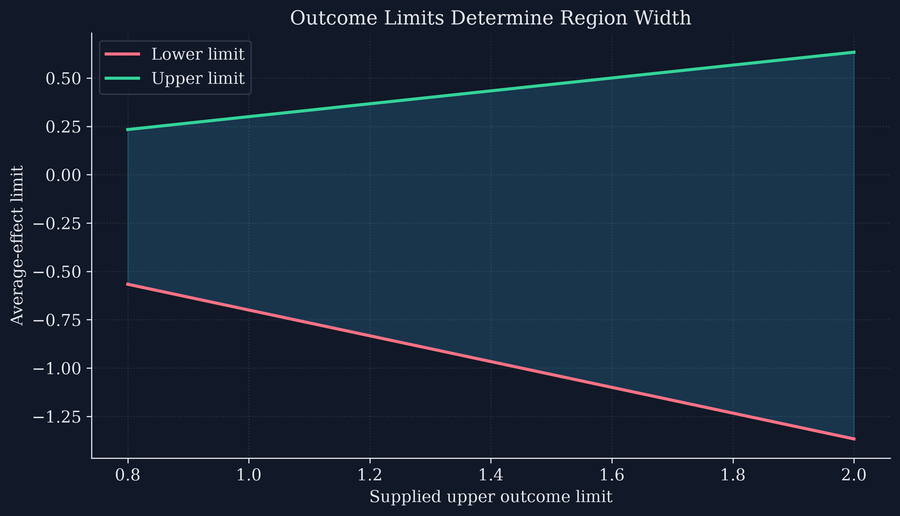

In [2]:
upper_grid = np.linspace(0.8, 2.0, 13)
range_records = []
for upper in upper_grid:
    result = manski_ate_bounds(observed, treatment, lower=0, upper=upper)
    range_records.append({"Upper outcome limit": upper, "Lower effect limit": result["lower"], "Upper effect limit": result["upper"], "Region width": result["upper"] - result["lower"]})
range_frame = pd.DataFrame(range_records)
save_table(range_frame, "manski_outcome_range_sensitivity", "Identification limits as the supplied upper outcome limit changes.", "tab:cim5-manski-range-sensitivity", fit=True)
range_frame.to_csv(FIGURE_DATA / "manski_outcome_range_sensitivity.csv", index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.0), constrained_layout=True)
axis.plot(range_frame["Upper outcome limit"], range_frame["Lower effect limit"], color=PALETTE["rose"], linewidth=2.2, label="Lower limit")
axis.plot(range_frame["Upper outcome limit"], range_frame["Upper effect limit"], color=PALETTE["green"], linewidth=2.2, label="Upper limit")
axis.fill_between(range_frame["Upper outcome limit"], range_frame["Lower effect limit"], range_frame["Upper effect limit"], color=PALETTE["cyan"], alpha=0.18)
axis.set_xlabel("Supplied upper outcome limit")
axis.set_ylabel("Average-effect limit")
axis.set_title("Outcome Limits Determine Region Width")
axis.legend()
finish_axis(axis)
save_figure(figure, "manski_outcome_range_sensitivity")

## A Public County-Panel Calculation

For each county, define a binary outcome that equals one when log employment rose from 2006 to 2007. The teaching calculation uses the fixed group indicator in the public panel as $D_i$. With $L=0$ and $U=1$, the natural outcome range is known. The resulting interval states what the observed binary outcomes and consistency alone imply for this empirical set of counties. It does not identify a minimum-wage effect because exchangeability is not assumed.

### Provenance of the public panel used for the bounded-outcome example

In [3]:
raw, counties = county_frame()
provenance = pd.DataFrame([{'Item': 'Public source', 'Value': "Callaway and Sant'Anna county panel"}, {'Item': 'Local file', 'Value': DATA_FILE.relative_to(BOOK_ROOT).as_posix()}, {'Item': 'File bytes', 'Value': DATA_FILE.stat().st_size}, {'Item': 'Panel rows', 'Value': len(raw)}, {'Item': 'Counties', 'Value': raw['countyreal'].nunique()}, {'Item': 'First year', 'Value': raw['year'].min()}, {'Item': 'Last year', 'Value': raw['year'].max()}, {'Item': 'Download during execution', 'Value': 'None'}])
save_table(provenance, 'mpdta_bound_provenance', 'Provenance of the public panel used for the bounded-outcome example.', 'tab:cim5-mpdta-bound-provenance', fit=True)
group_summary = counties.groupby('Treatment group').agg(Counties=('County identifier', 'size'), Employment_increase_rate=('Employment increased, 2006 to 2007', 'mean'), Mean_employment_change=('Employment change, 2003 to 2007', 'mean')).reset_index().rename(columns={'Treatment group': 'Treatment group', 'Employment_increase_rate': 'Employment increase rate', 'Mean_employment_change': 'Mean employment change'})
group_summary['Group'] = group_summary['Treatment group'].map({0: 'Never-treated group', 1: 'Treated cohort group'})
group_summary = group_summary[['Group', 'Counties', 'Employment increase rate', 'Mean employment change']]
save_table(group_summary, 'mpdta_binary_group_summary', 'Public county outcomes by the fixed group indicator.', 'tab:cim5-mpdta-binary-summary', fit=True)
public_bounds = manski_ate_bounds(counties['Employment increased, 2006 to 2007'].to_numpy(), counties['Treatment group'].to_numpy(), lower=0, upper=1)
public_bound_frame = pd.DataFrame([{'Quantity': 'Lower effect limit', 'Value': public_bounds['lower']}, {'Quantity': 'Upper effect limit', 'Value': public_bounds['upper']}, {'Quantity': 'Region width', 'Value': public_bounds['upper'] - public_bounds['lower']}, {'Quantity': 'Treatment fraction', 'Value': public_bounds['treated_fraction']}, {'Quantity': 'County count', 'Value': public_bounds['sample_count']}])
save_table(public_bound_frame, 'mpdta_binary_bounds', 'Worst-case limits for the public binary county outcome.', 'tab:cim5-mpdta-binary-bounds')
rate_data = group_summary[['Group', 'Employment increase rate']].copy()
rate_data.to_csv(FIGURE_DATA / 'mpdta_binary_rates.csv', index=False);


,Item,Value
0,Public source,Callaway and Sant'Anna county panel
1,Local file,data/public/callaway_santanna/mpdta.csv
2,File bytes,"124,867"
3,Panel rows,"2,500"
4,Counties,500
5,First year,"2,003"
6,Last year,"2,007"
7,Download during execution,None


,Group,Counties,Employment increase rate,Mean employment change
0,Never-treated group,309,0.585761,0.006503
1,Treated cohort group,191,0.486911,-0.032035


,Quantity,Value
0,Lower effect limit,-0.558
1,Upper effect limit,0.442
2,Region width,1
3,Treatment fraction,0.382
4,County count,500


### Observed County Outcomes by Group

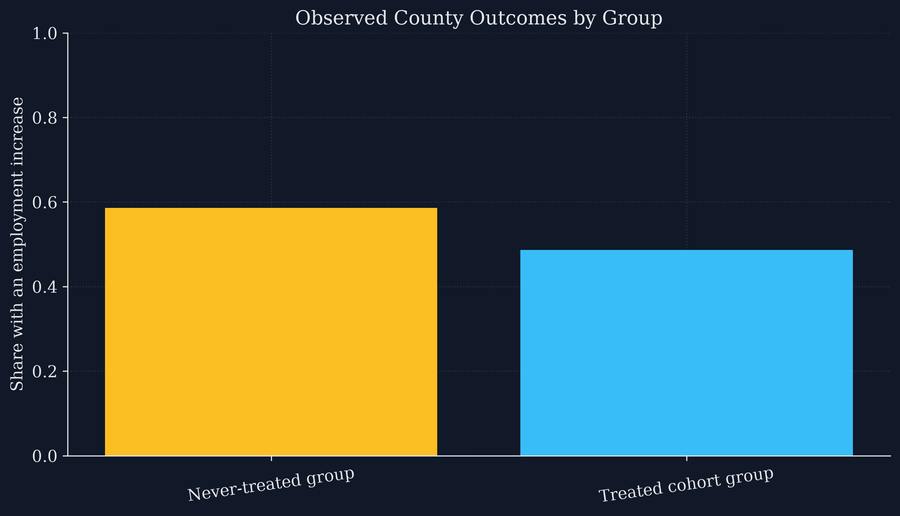

,Treatment fraction,Lower effect limit,Upper effect limit
0,0.05,-0.582127,0.417873
1,0.1,-0.578493,0.421507
2,0.15,-0.57486,0.42514
3,0.2,-0.571226,0.428774
4,0.25,-0.567593,0.432407
5,0.3,-0.563959,0.436041
6,0.35,-0.560325,0.439675
7,0.4,-0.556692,0.443308
8,0.45,-0.553058,0.446942
9,0.5,-0.549425,0.450575


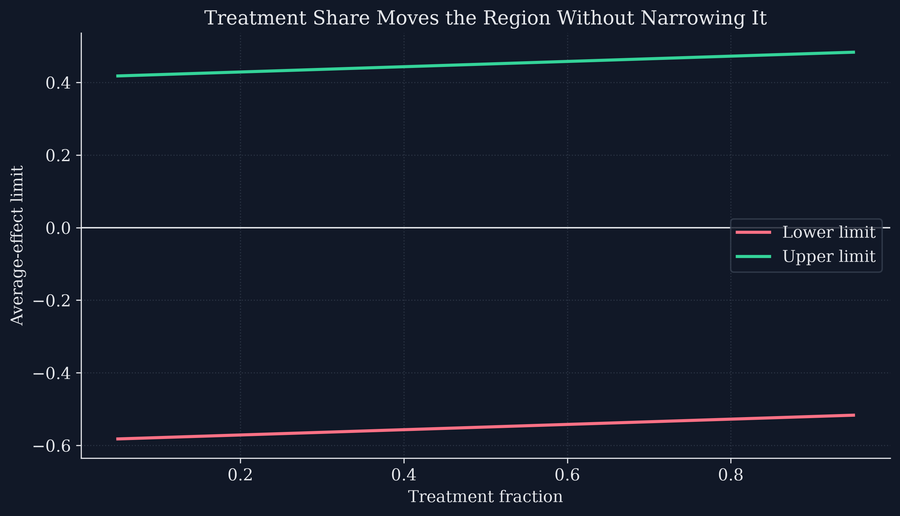

,Result,Value
0,Exact enumeration,Released limits equal the minimum and maximum ...
1,Boundary populations,All-treated and all-control inputs are accepted
2,Region width,Equals the supplied outcome range U minus L
3,Public example,Identification region only; no exchangeability...


,Result,Value
0,Exact enumeration,Released limits equal the minimum and maximum ...
1,Boundary populations,All-treated and all-control inputs are accepted
2,Region width,Equals the supplied outcome range U minus L
3,Public example,Identification region only; no exchangeability...


In [3]:
figure, axis = plt.subplots(figsize=(8.8, 5.0), constrained_layout=True)
axis.bar(rate_data['Group'], rate_data['Employment increase rate'], color=[PALETTE['amber'], PALETTE['cyan']])
axis.set_ylim(0, 1)
axis.set_ylabel('Share with an employment increase')
axis.set_title('Observed County Outcomes by Group')
axis.tick_params(axis='x', rotation=8)
finish_axis(axis)
save_figure(figure, 'mpdta_binary_rates')
treated_mean = counties.loc[counties['Treatment group'] == 1, 'Employment increased, 2006 to 2007'].mean()
control_mean = counties.loc[counties['Treatment group'] == 0, 'Employment increased, 2006 to 2007'].mean()
share_records = []
for share in np.linspace(0.05, 0.95, 19):
    lower = share * (treated_mean - 1) + (1 - share) * (0 - control_mean)
    upper = share * treated_mean + (1 - share) * (1 - control_mean)
    share_records.append({'Treatment fraction': share, 'Lower effect limit': lower, 'Upper effect limit': upper})
share_frame = pd.DataFrame(share_records)
save_table(share_frame, 'manski_treatment_share_sweep', 'Location of the binary-outcome limits as the treatment fraction changes.', 'tab:cim5-manski-treatment-share', fit=True)
share_frame.to_csv(FIGURE_DATA / 'manski_treatment_share_sweep.csv', index=False)
figure, axis = plt.subplots(figsize=(8.8, 5.0), constrained_layout=True)
axis.plot(share_frame['Treatment fraction'], share_frame['Lower effect limit'], color=PALETTE['rose'], linewidth=2.2, label='Lower limit')
axis.plot(share_frame['Treatment fraction'], share_frame['Upper effect limit'], color=PALETTE['green'], linewidth=2.2, label='Upper limit')
axis.axhline(0, color=PALETTE['text'], linewidth=1)
axis.set_xlabel('Treatment fraction')
axis.set_ylabel('Average-effect limit')
axis.set_title('Treatment Share Moves the Region Without Narrowing It')
axis.legend()
finish_axis(axis)
save_figure(figure, 'manski_treatment_share_sweep')
section_summary = pd.DataFrame([{'Result': 'Exact enumeration', 'Value': 'Released limits equal the minimum and maximum across all extreme completions'}, {'Result': 'Boundary populations', 'Value': 'All-treated and all-control inputs are accepted'}, {'Result': 'Region width', 'Value': 'Equals the supplied outcome range U minus L'}, {'Result': 'Public example', 'Value': 'Identification region only; no exchangeability or sampling claim'}])
save_table(section_summary, 'manski_section_summary', 'Summary of the bounded-outcome calculations.', 'tab:cim5-manski-section-summary', fit=True)
